# 02 – Knowledge graph & rule-based reasoning

The graph (built by `kg/build_kg.py`, enriched by `kg/reasoning.py`) is loaded from
`kg/output/kg.ttl`. This notebook shows its structure, the two inference rules, and the
district features derived with SPARQL.

```
Station ──locatedInDistrict──► District ◄──servesDistrict── Line ──hasMode──► TransportMode
   └────────servedByLine──────────────────────────────────────┘     (inferred)
District ──connectsTo──► District   (inferred)
```

In [1]:
import sys, warnings, logging
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1]))  # repository root (notebooks live in kg/notebooks/)
warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from kg.build_kg import load_kg
from kg.config import BASE_URI
g = load_kg()
P = f"PREFIX vn: <{BASE_URI}>\nPREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>\n"
print(f"{len(g):,} triples")

15,448 triples


## 1. What is in the graph?

In [3]:
q = P + "SELECT ?type (COUNT(?s) AS ?n) WHERE { ?s a ?type . FILTER(STRSTARTS(STR(?type), STR(vn:))) } GROUP BY ?type ORDER BY DESC(?n)"
pd.DataFrame([(str(r.type).rsplit('/', 1)[1], int(r.n)) for r in g.query(q)], columns=["class", "instances"])

,class,instances
0,Station,1746
1,Line,190
2,HousingListing,101
3,District,23
4,TransportMode,5


In [4]:
q = P + "SELECT ?p (COUNT(*) AS ?n) WHERE { ?s ?p ?o . FILTER(STRSTARTS(STR(?p), STR(vn:))) } GROUP BY ?p ORDER BY DESC(?n)"
pd.DataFrame([(str(r.p).rsplit('/', 1)[1], int(r.n)) for r in g.query(q)], columns=["property", "triples"])

,property,triples
0,servedByLine,4174
1,longitude,1847
2,latitude,1847
3,locatedInDistrict,1847
4,servesDistrict,496
5,connectsTo,394
6,hasMode,190
7,rent,101
8,rooms,101
9,size,101


## 2. Inference rules

Both rules are SPARQL `INSERT` statements (see `kg/reasoning.py`):

* **R1** a line *serves* a district if it stops at a station located in it
* **R2** two districts are *connected* if one daytime line serves both (night buses excluded)

The asserted graph only knows stations and lines; the rules lift that to the district level.

In [5]:
from kg.reasoning import RULE_SERVES_DISTRICT, RULE_CONNECTS_TO
print(RULE_SERVES_DISTRICT); print(RULE_CONNECTS_TO)

PREFIX vn: <http://example.org/vienna/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

INSERT { ?line vn:servesDistrict ?d }
WHERE  { ?station vn:servedByLine ?line ; vn:locatedInDistrict ?d . }

PREFIX vn: <http://example.org/vienna/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

INSERT { ?a vn:connectsTo ?b }
WHERE  {
  ?line vn:servesDistrict ?a, ?b ; vn:hasMode ?mode .
  FILTER (?a != ?b && ?mode != <http://example.org/vienna/mode/night_bus>)
}



## 3. Querying the enriched graph

Which lines take you from Ottakring (16) straight into the centre without changing?

In [6]:
q = P + f'''
SELECT ?line ?mode WHERE {{
  ?l vn:servesDistrict <{BASE_URI}district/16>, <{BASE_URI}district/1> ;
     rdfs:label ?line ; vn:hasMode/rdfs:label ?mode .
}} ORDER BY ?mode ?line'''
[(str(r.line), str(r.mode)) for r in g.query(q)]

[('48A', 'bus'),
 ('N46', 'night bus'),
 ('U3', 'subway'),
 ('2', 'tram'),
 ('44', 'tram'),
 ('46', 'tram'),
 ('49', 'tram')]

## 4. Derived district features

`compute_all_features` runs a handful of SPARQL queries and turns the results into three score
components in [0, 1] – the inputs of the match score shown in the app.

In [7]:
from kg.reasoning import compute_all_features
features = compute_all_features(g)
cols = ["name", "station_count", "line_count", "direct_lines_to_centre", "transit_density",
        "connectivity", "listing_count", "median_rent_per_sqm"]
table = pd.DataFrame(features).T[cols]
table.join(pd.DataFrame({d: f["components"] for d, f in features.items()}).T)

,name,station_count,line_count,direct_lines_to_centre,transit_density,connectivity,listing_count,median_rent_per_sqm,affordability,accessibility,transit
1,Innere Stadt,38,42,29,13.24,22,0,None,NaN,1.0000,1.0000
2,Leopoldstadt,85,22,6,4.42,17,3,9.13,0.8061,0.5455,0.2177
3,Landstraße,65,16,7,8.78,17,3,9.77,0.7309,0.6364,0.6048
4,Wieden,17,13,7,9.55,18,0,None,NaN,0.6364,0.6728
5,Margareten,25,14,5,12.44,18,2,None,NaN,0.4545,0.9288
6,Mariahilf,13,11,2,8.9,17,1,None,NaN,0.1818,0.6155
7,Neubau,20,15,5,12.42,20,0,None,NaN,0.4545,0.9275
8,Josefstadt,13,13,5,11.93,17,1,None,NaN,0.4545,0.8835
9,Alsergrund,26,22,11,8.75,21,0,None,NaN,1.0000,0.6022
10,Favoriten,133,34,6,4.18,19,16,9.04,0.8167,0.5455,0.1966


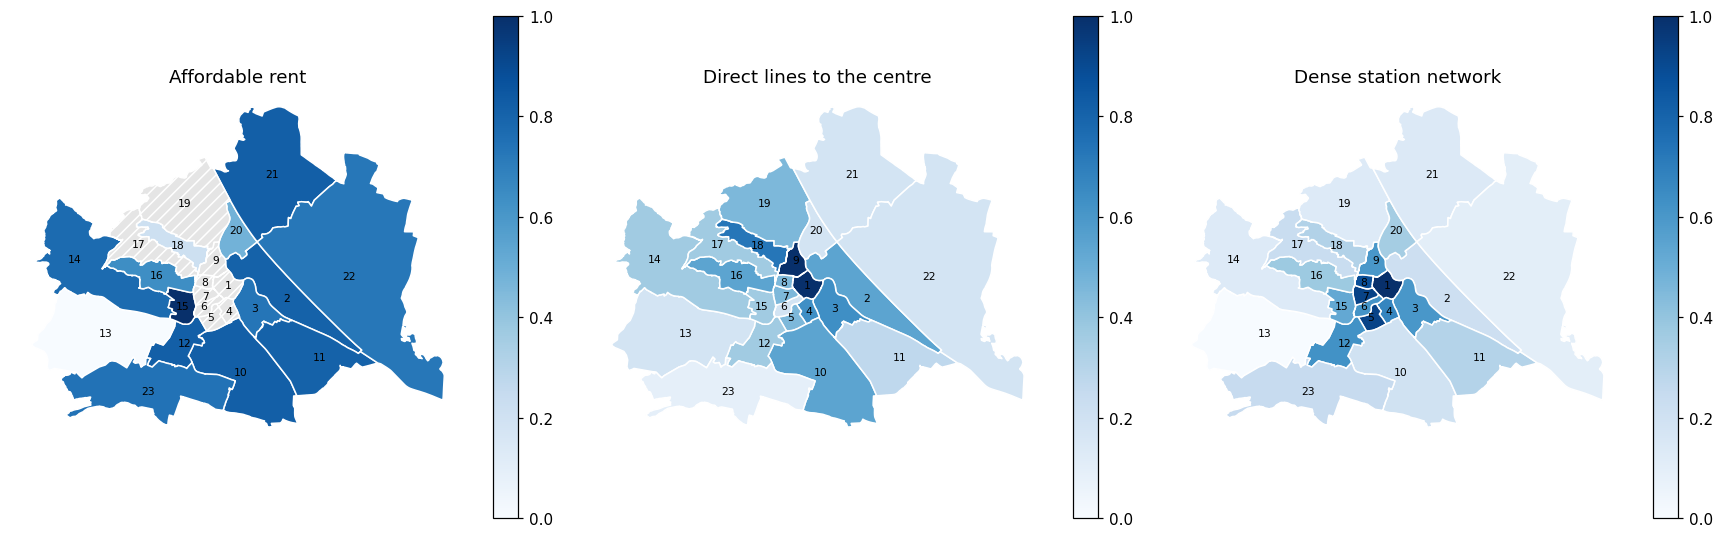

In [8]:
from kg.data.district_mapper import load_districts
districts = load_districts()
def choropleth(ax, values: dict, title: str, cmap="Blues", **kw):
    gdf = districts.assign(value=districts["district"].map(values))
    gdf.plot(column="value", ax=ax, cmap=cmap, edgecolor="white", linewidth=1, legend=True,
             missing_kwds={"color": "#e5e5e5", "hatch": "///", "label": "no data"}, **kw)
    for _, row in gdf.iterrows():
        c = row.geometry.representative_point()
        ax.annotate(str(row.district), (c.x, c.y), ha="center", va="center", fontsize=7)
    ax.set_title(title); ax.axis("off")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, comp, title in zip(axes, ["affordability", "accessibility", "transit"],
                           ["Affordable rent", "Direct lines to the centre", "Dense station network"]):
    choropleth(ax, {d: f["components"][comp] for d, f in features.items()}, title, vmin=0, vmax=1)
plt.tight_layout(); plt.show()

Observations: accessibility falls off with distance from the centre except along U-Bahn axes
(Alsergrund, Landstraße); station density is highest in the small inner districts; rent data is
missing for most inner districts because the sample only contains cheap listings.